In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_parquet('./velocity_diagnostics.parquet')
df.head()

,t,f_x,f_y,f_z,u_x,u_y,u_z,batch,tags
0,0.61296,0.007958,0.037056,0.131860,0.000000,0.000000,0.000000,0,0
1,0.61296,-0.051805,-0.074877,-0.038456,-0.092549,-0.069194,-0.087570,0,1
2,0.61296,-0.017013,-0.001570,-0.049690,0.000000,0.000000,0.000000,0,0
3,0.61296,0.047926,-0.117817,-0.139954,0.048446,-0.124928,-0.151793,0,1
4,0.61296,-0.018539,-0.054489,-0.250089,0.000000,0.000000,0.000000,0,0


In [3]:
import matplotlib.pyplot as plt

# Extract as numpy arrays
t = df['t'].values
f = df[['f_x', 'f_y', 'f_z']].values  # predicted velocity (N, 3)
u = df[['u_x', 'u_y', 'u_z']].values  # target velocity (N, 3)
batch = df['batch'].values
tags = df['tags'].values

# Per-atom error (L2 norm of velocity difference)
error = np.linalg.norm(f - u, axis=1)  # (N,)
drift = (f - u).mean(axis=1)  # (3,)

# Masks
is_adsorbate = (tags == 2)
is_catalyst = (tags == 1)

print(f'Total atoms: {len(t):,}')
print(f'Adsorbate atoms: {is_adsorbate.sum():,}')
print(f'Catalyst atoms: {is_catalyst.sum():,}')
print()
print(f'Overall MAE:    {error.mean():.4f}')
print(f'Catalyst MAE:   {error[is_catalyst].mean():.4f}')
print(f'Adsorbate MAE:  {error[is_adsorbate].mean():.4f}')

print()
print(f'Overall drift:    {drift.mean():.4f}')
print(f'Catalyst drift:   {drift[is_catalyst].mean():.4f}')
print(f'Adsorbate drift:  {drift[is_adsorbate].mean():.4f}')



Total atoms: 780,763
Adsorbate atoms: 46,893
Catalyst atoms: 206,910

Overall MAE:    0.0857
Catalyst MAE:   0.0533
Adsorbate MAE:  0.2794

Overall drift:    0.0016
Catalyst drift:   -0.0006
Adsorbate drift:  -0.0005


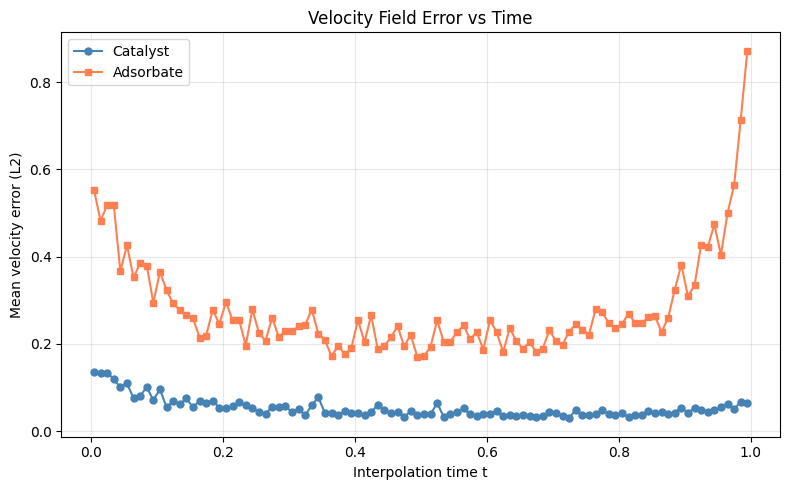

In [4]:
# Bin errors by time
n_bins = 100
t_bins = np.linspace(0, 1, n_bins + 1)
t_centers = 0.5 * (t_bins[:-1] + t_bins[1:])

def binned_mean_error(t_vals, errors, bins):
    bin_idx = np.clip(np.digitize(t_vals, bins) - 1, 0, len(bins) - 2)
    means = np.array([errors[bin_idx == i].mean() if (bin_idx == i).any() else np.nan
                      for i in range(len(bins) - 1)])
    return means

cat_means = binned_mean_error(t[is_catalyst], error[is_catalyst], t_bins)
ads_means = binned_mean_error(t[is_adsorbate], error[is_adsorbate], t_bins)

# Plot: Error vs time
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_centers, cat_means, 'o-', label='Catalyst', color='steelblue', markersize=5)
ax.plot(t_centers, ads_means, 's-', label='Adsorbate', color='coral', markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity error (L2)')
ax.set_title('Velocity Field Error vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

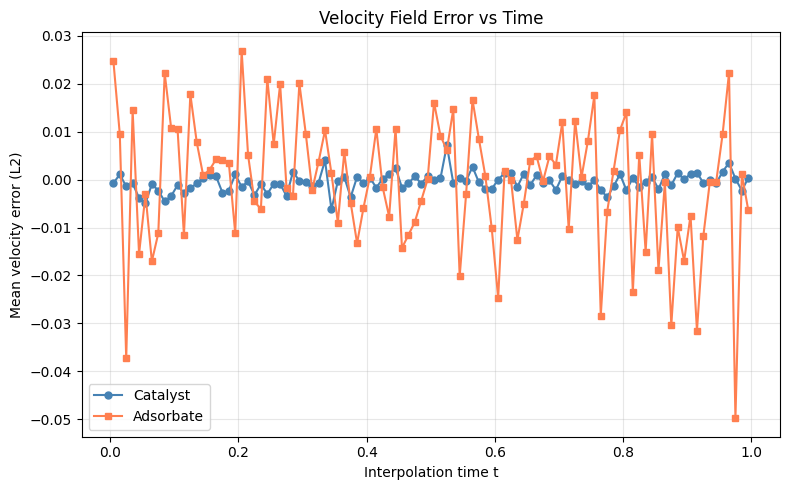

In [5]:
# Bin errors by time
n_bins = 100
t_bins = np.linspace(0, 1, n_bins + 1)
t_centers = 0.5 * (t_bins[:-1] + t_bins[1:])

cat_means = binned_mean_error(t[is_catalyst], drift[is_catalyst], t_bins)
ads_means = binned_mean_error(t[is_adsorbate], drift[is_adsorbate], t_bins)

# Plot: Error vs time
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_centers, cat_means, 'o-', label='Catalyst', color='steelblue', markersize=5)
ax.plot(t_centers, ads_means, 's-', label='Adsorbate', color='coral', markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity error (L2)')
ax.set_title('Velocity Field Error vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()